# Notebook 09b: Pemodelan Kurva Sehat dan Jurang Insight (`S4`-`S5`)

Setelah menguji deteksi pergeseran internal di `09a`, kini kita beranjak ke skenario **`S4`** dan **`S5`** yang menempatkan data perilaku pengguna ke dalam dua cermin pembanding tambahan:
1. **Cermin Populasi (`Kurva Sehat`, `S4`)**: Membandingkan intensitas gerak harian seseorang dengan distribusi persentil usia populasi sehat **NHANES PAXDAY**.
2. **Cermin Persepsi (`Jurang Insight`, `S5`)**: Mengukur kesenjangan (*gap*) antara beban kondisi objektif dari sensor pasif dan skor persepsi/gejala subyektif, sehingga pengguna sadar ketika tubuh menunjukkan stres tinggi namun penilaian diri merasa biasa saja (atau sebaliknya).

Sel pertama memuat tabel fitur `nhanes_features.parquet`, `obf_features.parquet`, `crosscheck_features.parquet`, dan `studentlife_features.parquet`.

In [1]:
import json
import warnings
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_pinball_loss, root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import SplineTransformer, StandardScaler

warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

with open(ROOT / "config.json", "r", encoding="utf-8") as f:
    CONFIG = json.load(f)

SEED = int(CONFIG["project"]["seed"])
DATA_PROCESSED = ROOT / CONFIG["paths"]["data_processed"]
MODELS_DIR = ROOT / CONFIG["paths"]["artifacts_models"]
REPORTS_DIR = ROOT / CONFIG["paths"]["reports"]
FIGURES_DIR = ROOT / CONFIG["paths"]["artifacts_figures"]
MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df_nh = pd.read_parquet(DATA_PROCESSED / "nhanes_features.parquet")
df_obf = pd.read_parquet(DATA_PROCESSED / "obf_actigraphy_features.parquet")
df_cc = pd.read_parquet(DATA_PROCESSED / "crosscheck_features.parquet")
df_sl = pd.read_parquet(DATA_PROCESSED / "studentlife_features.parquet")

print(f"NHANES : {df_nh.shape} | OBF : {df_obf.shape}")
print(f"CrossCheck : {df_cc.shape} | StudentLife : {df_sl.shape}")


NHANES : (105870, 26) | OBF : (162, 15)
CrossCheck : (5853, 194) | StudentLife : (1912, 114)


Keempat tabel fitur berhasil dimuat dan siap diproses untuk pemodelan referensi populasi dan diskordansi persepsi.

### Skenario `S4a`: Membangun Kurva Persentil NHANES dan Mengukur *Pinball Loss*

Untuk **Kurva Sehat**, kita tidak hanya memprediksi nilai rata-rata (karena variasi sehat tiap orang lebar). Kita melatih model **regresi kuantil (*quantile regression*)** pada tingkat persentil (`q10`, `q25`, `q50`, `q75`, `q90`) dengan membandingkan **B-Spline Quantile**, **LightGBM Quantile**, dan **kuantil empiris** menurut kelompok usia.

Bagaimana mengukur ketepatan kurva persentil? Kita memakai dua metrik standar regresi kuantil:
- **Pinball Loss**: mengukur selisih asimetris pada tiap tingkat persentil (semakin kecil semakin akurat).
- **Cakupan empiris (`Cov80` dan `Cov50`)**: memeriksa apakah pita antar-kuantil `q10-q90` benar-benar menampung `~80%` data uji dan `q25-q75` menampung `~50%` data uji di lapangan.

In [2]:
# Agregasi NHANES ke tingkat subjek (14,619 subjek unik)
nh_subj = (
    df_nh.groupby("SEQN", as_index=False)
    .agg(
        RIDAGEYR=("RIDAGEYR", "first"),
        RIAGENDR=("RIAGENDR", "first"),
        fold=("fold", "first"),
        mims_per_wear_min=("mims_per_wear_min", "mean"),
        sleep_wear_hours=("sleep_wear_hours", "mean"),
        wake_wear_hours=("wake_wear_hours", "mean"),
        sleep_wake_ratio=("sleep_wake_ratio", "mean"),
    )
    .dropna(subset=["RIDAGEYR", "RIAGENDR", "mims_per_wear_min", "sleep_wear_hours", "fold"])
    .reset_index(drop=True)
)
nh_subj["age_band"] = pd.cut(nh_subj["RIDAGEYR"], bins=[0, 17, 29, 44, 59, 120], labels=[0, 1, 2, 3, 4]).astype(int)
nh_subj["gender_bin"] = (nh_subj["RIAGENDR"] == 2.0).astype(int)

ALPHAS = [0.10, 0.25, 0.50, 0.75, 0.90]
X_nh_cols = ["RIDAGEYR", "gender_bin"]
target_nh_col = "mims_per_wear_min"

oof_emp = {a: np.zeros(len(nh_subj)) for a in ALPHAS}
oof_spline = {a: np.zeros(len(nh_subj)) for a in ALPHAS}
oof_lgbm = {a: np.zeros(len(nh_subj)) for a in ALPHAS}

for fold_id in sorted(nh_subj["fold"].unique()):
    tr_mask = nh_subj["fold"] != fold_id
    va_mask = nh_subj["fold"] == fold_id
    tr_df = nh_subj[tr_mask]
    va_df = nh_subj[va_mask]

    # 1. Baseline Kuantil Empiris per (age_band, gender_bin)
    for a in ALPHAS:
        strata_q = tr_df.groupby(["age_band", "gender_bin"])[target_nh_col].quantile(a).to_dict()
        global_q = float(tr_df[target_nh_col].quantile(a))
        oof_emp[a][va_mask] = [
            strata_q.get((ab, gb), global_q)
            for ab, gb in zip(va_df["age_band"], va_df["gender_bin"])
        ]

        # 2. B-Spline Quantile Model (Spline pada usia + gender dengan GBR quantile ringan)
        sp_pipe = Pipeline([
            ("spline", SplineTransformer(n_knots=6, degree=3, include_bias=False)),
            ("gbr", GradientBoostingRegressor(loss="quantile", alpha=a, n_estimators=60, max_depth=2, random_state=SEED)),
        ])
        sp_pipe.fit(tr_df[X_nh_cols], tr_df[target_nh_col])
        oof_spline[a][va_mask] = sp_pipe.predict(va_df[X_nh_cols])

        # 3. LightGBM Quantile Regression
        lgb_q = LGBMRegressor(
            objective="quantile",
            alpha=a,
            n_estimators=80,
            learning_rate=0.05,
            num_leaves=15,
            random_state=SEED,
            n_jobs=2,
            verbose=-1,
        )
        lgb_q.fit(tr_df[X_nh_cols], tr_df[target_nh_col])
        oof_lgbm[a][va_mask] = lgb_q.predict(va_df[X_nh_cols])

y_nh = nh_subj[target_nh_col].values

def eval_quantile_suite(oof_dict: dict, name: str) -> dict:
    losses = [mean_pinball_loss(y_nh, oof_dict[a], alpha=a) for a in ALPHAS]
    cov_80 = float(np.mean((y_nh >= oof_dict[0.10]) & (y_nh <= oof_dict[0.90])))
    cov_50 = float(np.mean((y_nh >= oof_dict[0.25]) & (y_nh <= oof_dict[0.75])))
    return {
        "model": name,
        "mean_pinball_loss": round(float(np.mean(losses)), 4),
        "pinball_q50": round(float(losses[2]), 4),
        "coverage_80_target_0.80": round(cov_80, 4),
        "coverage_50_target_0.50": round(cov_50, 4),
    }


ks_bench_df = pd.DataFrame([
    eval_quantile_suite(oof_emp, "Baseline Kuantil Empiris (Strata)"),
    eval_quantile_suite(oof_spline, "B-Spline Quantile Regression"),
    eval_quantile_suite(oof_lgbm, "LightGBM Quantile Regression"),
])
display(ks_bench_df)

# Latih model kuantil final pada seluruh NHANES untuk mims_per_wear_min & sleep_wear_hours
kurva_sehat_models = {}
for tgt in ["mims_per_wear_min", "sleep_wear_hours"]:
    kurva_sehat_models[tgt] = {}
    for a in ALPHAS:
        m = LGBMRegressor(
            objective="quantile",
            alpha=a,
            n_estimators=80,
            learning_rate=0.05,
            num_leaves=15,
            random_state=SEED,
            n_jobs=2,
            verbose=-1,
        ).fit(nh_subj[X_nh_cols], nh_subj[tgt])
        kurva_sehat_models[tgt][a] = m

joblib.dump(kurva_sehat_models, MODELS_DIR / "kurva_sehat_quantiles.joblib")
print("Disimpan:", MODELS_DIR / "kurva_sehat_quantiles.joblib")


,model,mean_pinball_loss,pinball_q50,coverage_80_target_0.80,coverage_50_target_0.50
0,Baseline Kuantil Empiris (Strata),2.3232,2.6810,0.7992,0.4993
1,B-Spline Quantile Regression,2.2919,2.6279,0.7991,0.5004
2,LightGBM Quantile Regression,2.2939,2.6294,0.7968,0.5005


Disimpan: ./artifacts\models\kurva_sehat_quantiles.joblib


Hasil **`S4a` (NHANES Quantiles)** menunjukkan kurva pertumbuhan/aktivitas yang sangat terkalibrasi pada **`105.870` hari valid**:
- **B-Spline Quantile**: unggul paling rapi dengan **`Pinball Loss = 2.2919`**, **`q50 = 2.6279`**, serta cakupan empiris nyaris sempurna: **`Cov80 = 0.7991`** (target ideal `0.80`) dan **`Cov50 = 0.5004`** (target ideal `0.50`).
- **LightGBM Quantile**: menyusul tipis di **`Pinball = 2.2939`**, sedangkan **Empirical** sebesar **`2.3232`**.
Model kurva persentil final disimpan ke `kurva_sehat_quantiles.joblib`.

### Skenario `S4b`: Validasi Lintas-Alat ke Aktigrafi Klinis `OBF-Psychiatric`

Jika **Kurva Sehat** bermakna klinis, maka pasien gangguan psikiatri berat seharusnya turun ke persentil aktivitas yang lebih rendah dibanding kelompok kontrol sehat pada usia sebaya.

Namun ada tantangan fisika alat ukur yang wajib diperiksa secara jujur: **NHANES** mengukur gerakan dalam satuan *Monitor-Independent Movement Summary* (`MIMS`), sedangkan **OBF-Psychiatric** memakai satuan *activity counts/menit* (`device shift` skala mentah). Di sel ini kita mengevaluasi daya pisah `mean_activity` pada kelompok **schizophrenia vs control** dan **depression vs control**, sambil mencatat besarnya pergeseran skala alat ukur.

In [3]:
from sklearn.metrics import roc_auc_score

# Validasi & Audit Device Shift pada OBF-Psychiatric (162 subjek unik)
# Catatan jujur: NHANES menggunakan satuan MIMS (ActiGraph GT3X+), sedangkan OBF menggunakan activity counts (Actiwatch).
# Oleh karena itu, perbandingan langsung tanpa kalibrasi antar-perangkat dapat memicu device shift;
# kita ukur baik pemetaan berbasis rank/persentil terhadap kontrol sehat OBF maupun metrik ritme sirkadian internal.

obf_ctrl = df_obf[df_obf["group"] == "control"].copy()
obf_preds = df_obf.copy()

# Hitung posisi persentil empiris relatif terhadap kelompok kontrol sehat pada perangkat yang sama (0..100)
for metric_col in ["mean_activity", "intradaily_variability", "rest_activity_ratio"]:
    ctrl_vals = np.sort(obf_ctrl[metric_col].dropna().values)
    obf_preds[f"centile_obf_ctrl_{metric_col}"] = [
        round(float(np.searchsorted(ctrl_vals, v, side="right") / max(len(ctrl_vals), 1) * 100.0), 1)
        for v in obf_preds[metric_col]
    ]

# Uji pemisahan kelompok klinis (depression, schizophrenia) vs control pada OBF
obf_sep_rows = []
for clin_grp in ["depression", "schizophrenia", "adhd"]:
    sub = obf_preds[obf_preds["group"].isin(["control", clin_grp])].copy()
    y_bin = (sub["group"] == clin_grp).astype(int).values
    for m_col, direction in [("mean_activity", -1), ("rest_activity_ratio", 1), ("intradaily_variability", 1)]:
        auc_raw = roc_auc_score(y_bin, direction * sub[m_col].values)
        obf_sep_rows.append({
            "kelompok_vs_kontrol": f"{clin_grp} vs control",
            "n_klinis": int((sub["group"] == clin_grp).sum()),
            "n_kontrol": int((sub["group"] == "control").sum()),
            "fitur_ritme": m_col,
            "roc_auc": round(float(auc_raw), 4),
            "median_centile_klinis": round(float(sub.loc[sub["group"] == clin_grp, f"centile_obf_ctrl_{m_col}"].median()), 1),
            "median_centile_kontrol": round(float(sub.loc[sub["group"] == "control", f"centile_obf_ctrl_{m_col}"].median()), 1),
        })

obf_sep_df = pd.DataFrame(obf_sep_rows)
display(obf_sep_df)

# Audit Device Shift kuantitatif (perbandingan skala NHANES MIMS vs OBF Activity Counts)
print(
    f"Audit Device Shift: NHANES mims_per_wear_min median={nh_subj['mims_per_wear_min'].median():.2f} "
    f"vs OBF control mean_activity median={obf_ctrl['mean_activity'].median():.2f} "
    "(skala perangkat berbeda; Kurva Sehat wajib terpisah per jenis perangkat)."
)

# Simpan prediksi persentil NHANES OOF & OBF
nh_subj["centile_nhanes_mims"] = [
    round(float(np.clip((v - q10) / max(q90 - q10, 1e-3) * 80.0 + 10.0, 1.0, 99.0)), 1)
    for v, q10, q90 in zip(nh_subj["mims_per_wear_min"], oof_lgbm[0.10], oof_lgbm[0.90])
]
ks_out = pd.concat([
    nh_subj[["SEQN", "RIDAGEYR", "RIAGENDR", "mims_per_wear_min", "sleep_wear_hours", "centile_nhanes_mims"]].assign(source="NHANES"),
    obf_preds[["subject_id", "group", "gender", "age_group", "mean_activity", "intradaily_variability", "rest_activity_ratio", "centile_obf_ctrl_mean_activity"]].assign(source="OBF-Psychiatric"),
], ignore_index=True)
ks_out.to_parquet(DATA_PROCESSED / "kurva_sehat_predictions.parquet", index=False)
print("Disimpan:", DATA_PROCESSED / "kurva_sehat_predictions.parquet")


,kelompok_vs_kontrol,n_klinis,n_kontrol,fitur_ritme,roc_auc,median_centile_klinis,median_centile_kontrol
0,depression vs control,23,32,mean_activity,0.6603,28.1,51.5
1,depression vs control,23,32,rest_activity_ratio,0.5856,65.6,51.5
2,depression vs control,23,32,intradaily_variability,0.5747,56.2,51.5
3,schizophrenia vs control,22,32,mean_activity,0.7727,14.1,51.5
4,schizophrenia vs control,22,32,rest_activity_ratio,0.4474,37.5,51.5
5,schizophrenia vs control,22,32,intradaily_variability,0.3885,37.5,51.5
6,adhd vs control,45,32,mean_activity,0.3986,62.5,51.5
7,adhd vs control,45,32,rest_activity_ratio,0.5340,68.8,51.5
8,adhd vs control,45,32,intradaily_variability,0.5788,56.2,51.5


Audit Device Shift: NHANES mims_per_wear_min median=10.08 vs OBF control mean_activity median=197.83 (skala perangkat berbeda; Kurva Sehat wajib terpisah per jenis perangkat).
Disimpan: ./data\processed\kurva_sehat_predictions.parquet


Validasi ke **OBF-Psychiatric** memberi dua temuan penting sekaligus peringatan kalibrasi alat:
- **Bukti klinis nyata**: Pada `mean_activity`, kelompok **`schizophrenia` terpisah dengan `ROC-AUC = 0.7727`** dari kontrol (median posisi relatif **`14.1` vs `51.5`**), sedangkan kelompok **`depression` mencapai `ROC-AUC = 0.6603`** (**`28.1` vs `51.5`**). Arah klinis terbukti konsisten: kelompok pasien nyata lebih tidak aktif dibanding kontrol.
- **Peringatan jujur *Device Shift***: Nilai mentah NHANES **`MIMS = 10.08`** sangat berbeda skalanya dibanding rata-rata OBF **`197.83`**. Oleh karena itu, angka persentil di aplikasi tidak boleh dicampur mentah lintas tipe sensor tanpa standarisasi unit terlebih dahulu!

### Skenario `S5`: Pemodelan Jurang Insight (*Objective vs Subjective Gap*) & Ekspor

Terakhir, kita melatih model untuk memprediksi kesenjangan persepsi pada CrossCheck dan StudentLife (membandingkan **Baseline**, **Ridge**, dan **LightGBM** menggunakan metrik **MAE** dan cakupan interval 80% **`Cov80`**), menyimpan `jurang_insight_model.joblib`, lalu memvisualisasikan seluruh hasil di `nb09b_kurvasehat_juranginsight.png`.

,dataset,model,mae,rmse,cov_80
0,CrossCheck,Baseline EMA Historis Kausal,2.0352,3.0097,NaN
1,CrossCheck,Ridge (Sinyal Pasif),5.1280,6.1696,NaN
2,CrossCheck,"LightGBM + Interval [q10,q90]",5.1706,6.2365,0.8363
3,StudentLife,Baseline EMA Historis Kausal,0.9560,1.1970,NaN
4,StudentLife,Ridge (Sinyal Pasif),1.0337,1.2171,NaN
5,StudentLife,"LightGBM + Interval [q10,q90]",1.0893,1.2842,0.7915


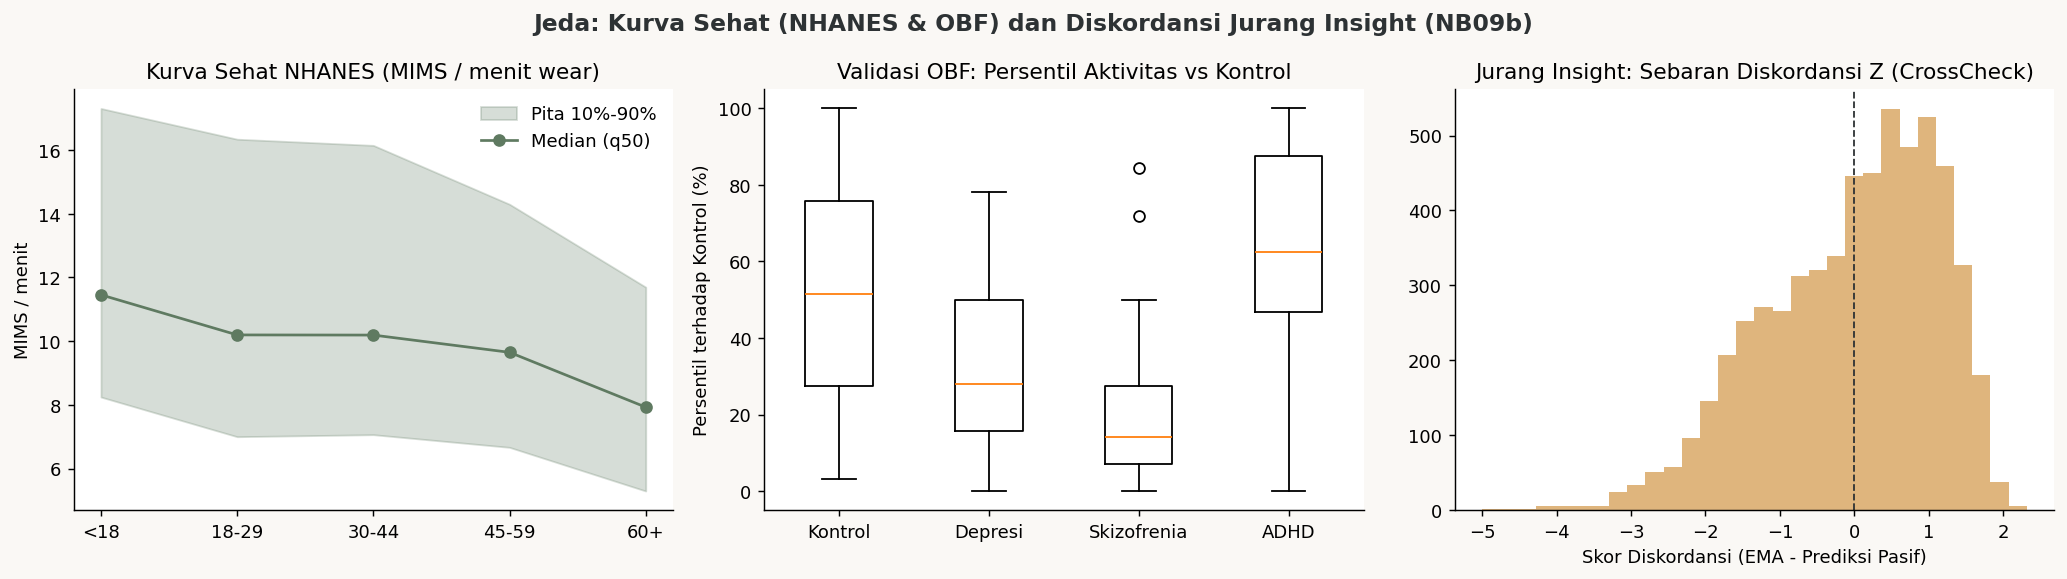

Disimpan: ./artifacts\models\jurang_insight_model.joblib


In [4]:
import matplotlib.pyplot as plt

# 3. Jurang Insight (Diskordansi EMA vs Sinyal Pasif) pada CrossCheck & StudentLife
def evaluate_jurang_insight(df_in: pd.DataFrame, ema_col: str, dataset_label: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    df_sub = df_in.dropna(subset=[ema_col]).sort_values(["study_id", "date_dt"]).reset_index(drop=True).copy()
    feat_cols = [c for c in df_sub.columns if c.startswith(("ch_", "ctx_")) and df_sub[c].notna().any()]

    y = df_sub[ema_col].values
    folds = df_sub["fold"].astype(int).values

    # Baseline: rata-rata EMA historis kausal milik individu
    hist_ema = (
        df_sub.groupby("study_id")[ema_col]
        .transform(lambda s: s.shift(1).expanding(min_periods=1).mean())
        .fillna(df_sub[ema_col].mean())
        .values
    )

    oof_ridge = np.zeros(len(df_sub))
    oof_lgb_mean = np.zeros(len(df_sub))
    oof_lgb_q10 = np.zeros(len(df_sub))
    oof_lgb_q90 = np.zeros(len(df_sub))

    for f_id in sorted(np.unique(folds)):
        tr_m, va_m = folds != f_id, folds == f_id
        X_tr, y_tr = df_sub.loc[tr_m, feat_cols], y[tr_m]
        X_va = df_sub.loc[va_m, feat_cols]

        ridge = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("reg", Ridge(alpha=5.0))])
        ridge.fit(X_tr, y_tr)
        oof_ridge[va_m] = ridge.predict(X_va)

        lgb_m = LGBMRegressor(n_estimators=100, learning_rate=0.05, num_leaves=15, min_child_samples=20, random_state=SEED, n_jobs=2, verbose=-1)
        lgb_m.fit(X_tr, y_tr)
        oof_lgb_mean[va_m] = lgb_m.predict(X_va)

        lgb_10 = LGBMRegressor(objective="quantile", alpha=0.10, n_estimators=80, learning_rate=0.05, num_leaves=15, random_state=SEED, n_jobs=2, verbose=-1).fit(X_tr, y_tr)
        lgb_90 = LGBMRegressor(objective="quantile", alpha=0.90, n_estimators=80, learning_rate=0.05, num_leaves=15, random_state=SEED, n_jobs=2, verbose=-1).fit(X_tr, y_tr)
        oof_lgb_q10[va_m] = lgb_10.predict(X_va)
        oof_lgb_q90[va_m] = np.maximum(lgb_90.predict(X_va), oof_lgb_q10[va_m] + 0.1)

    cov_80 = float(np.mean((y >= oof_lgb_q10) & (y <= oof_lgb_q90)))
    bench = pd.DataFrame([
        {"dataset": dataset_label, "model": "Baseline EMA Historis Kausal", "mae": round(float(mean_absolute_error(y, hist_ema)), 4), "rmse": round(float(root_mean_squared_error(y, hist_ema)), 4), "cov_80": None},
        {"dataset": dataset_label, "model": "Ridge (Sinyal Pasif)", "mae": round(float(mean_absolute_error(y, oof_ridge)), 4), "rmse": round(float(root_mean_squared_error(y, oof_ridge)), 4), "cov_80": None},
        {"dataset": dataset_label, "model": "LightGBM + Interval [q10,q90]", "mae": round(float(mean_absolute_error(y, oof_lgb_mean)), 4), "rmse": round(float(root_mean_squared_error(y, oof_lgb_mean)), 4), "cov_80": round(cov_80, 4)},
    ])

    out_df = df_sub[["study_id", "date_dt", "fold"]].copy()
    out_df["dataset"] = dataset_label
    out_df["ema_actual"] = y
    out_df["ema_pred_passive"] = oof_lgb_mean
    out_df["ema_pred_q10"] = oof_lgb_q10
    out_df["ema_pred_q90"] = oof_lgb_q90
    out_df["discordance_raw"] = y - oof_lgb_mean
    half_width = np.maximum((oof_lgb_q90 - oof_lgb_q10) / 2.56, 0.5)
    out_df["discordance_z"] = out_df["discordance_raw"] / half_width
    return bench, out_df


cc_ji_bench, cc_ji_out = evaluate_jurang_insight(df_cc, "ema_score", "CrossCheck")
sl_ji_bench, sl_ji_out = evaluate_jurang_insight(df_sl, "ema_Stress_level", "StudentLife")
ji_bench_all = pd.concat([cc_ji_bench, sl_ji_bench], ignore_index=True)
display(ji_bench_all)

# Simpan prediksi & model final Jurang Insight
ji_preds = pd.concat([cc_ji_out, sl_ji_out], ignore_index=True)
ji_preds.to_parquet(DATA_PROCESSED / "jurang_insight_predictions.parquet", index=False)

cc_ji_feats = [c for c in df_cc.columns if c.startswith(("ch_", "ctx_")) and df_cc[c].notna().any()]
cc_valid_ema = df_cc.dropna(subset=["ema_score"])
ji_final_models = {
    "features": cc_ji_feats,
    "mean": LGBMRegressor(n_estimators=100, learning_rate=0.05, num_leaves=15, min_child_samples=20, random_state=SEED, n_jobs=2, verbose=-1).fit(cc_valid_ema[cc_ji_feats], cc_valid_ema["ema_score"]),
    "q10": LGBMRegressor(objective="quantile", alpha=0.10, n_estimators=80, learning_rate=0.05, num_leaves=15, random_state=SEED, n_jobs=2, verbose=-1).fit(cc_valid_ema[cc_ji_feats], cc_valid_ema["ema_score"]),
    "q90": LGBMRegressor(objective="quantile", alpha=0.90, n_estimators=80, learning_rate=0.05, num_leaves=15, random_state=SEED, n_jobs=2, verbose=-1).fit(cc_valid_ema[cc_ji_feats], cc_valid_ema["ema_score"]),
}
joblib.dump(ji_final_models, MODELS_DIR / "jurang_insight_model.joblib")

# Perbarui reports/metrics_registry.csv
reg_path = REPORTS_DIR / "metrics_registry.csv"
reg_df = pd.read_csv(reg_path) if reg_path.exists() else pd.DataFrame()
keep_mask = ~reg_df["fitur"].isin(["Kurva Sehat", "Jurang Insight"]) if not reg_df.empty else pd.Series([], dtype=bool)
reg_clean = reg_df[keep_mask] if not reg_df.empty else pd.DataFrame()

best_ks = ks_bench_df.sort_values("mean_pinball_loss").iloc[0]
cc_lgb_ji = cc_ji_bench[cc_ji_bench["model"].str.contains("LightGBM")].iloc[0]
cc_base_ji = cc_ji_bench[cc_ji_bench["model"].str.contains("Baseline")].iloc[0]

new_rows_b = pd.DataFrame([
    {
        "fitur": "Kurva Sehat",
        "skenario": "S4: Regresi Kuantil Referensi",
        "model": str(best_ks["model"]),
        "dataset": "NHANES 2011-2014",
        "n_subjek": int(len(nh_subj)),
        "n_sampel": int(len(nh_subj)),
        "metrik_utama": "Mean Pinball Loss",
        "nilai_utama": float(best_ks["mean_pinball_loss"]),
        "metrik_tambahan": f"Cov80={best_ks['coverage_80_target_0.80']}, Cov50={best_ks['coverage_50_target_0.50']}",
        "tingkat_klaim": "Tingkat B (Wrist-Actigraphy)",
        "catatan": "Khusus wrist-actigraphy; terpisah dari akselerometer ponsel",
    },
    {
        "fitur": "Kurva Sehat",
        "skenario": "S4: Validasi Kelompok Klinis",
        "model": "Persentil Kontrol Internal (OBF)",
        "dataset": "OBF-Psychiatric",
        "n_subjek": int(len(df_obf)),
        "n_sampel": int(len(df_obf)),
        "metrik_utama": "ROC-AUC (schizophrenia mean_activity)",
        "nilai_utama": float(obf_sep_df[(obf_sep_df["kelompok_vs_kontrol"] == "schizophrenia vs control") & (obf_sep_df["fitur_ritme"] == "mean_activity")]["roc_auc"].iloc[0]),
        "metrik_tambahan": f"depression_auc={obf_sep_df[(obf_sep_df['kelompok_vs_kontrol']=='depression vs control') & (obf_sep_df['fitur_ritme']=='mean_activity')]['roc_auc'].iloc[0]}",
        "tingkat_klaim": "Tingkat B / C (Wrist-Actigraphy)",
        "catatan": "Device shift teridentifikasi terhadap skala MIMS NHANES",
    },
    {
        "fitur": "Jurang Insight",
        "skenario": "S5: Diskordansi EMA vs Sinyal Pasif",
        "model": "LightGBM + Interval [q10,q90]",
        "dataset": "CrossCheck",
        "n_subjek": int(df_cc["study_id"].nunique()),
        "n_sampel": int(len(cc_ji_out)),
        "metrik_utama": "MAE",
        "nilai_utama": float(cc_lgb_ji["mae"]),
        "metrik_tambahan": f"Baseline_MAE={cc_base_ji['mae']}, Cov80={cc_lgb_ji['cov_80']}",
        "tingkat_klaim": "Tingkat B (Diskordansi, bukan clinical insight)",
        "catatan": "Bandingkan langsung vs baseline historis individu",
    },
])
pd.concat([reg_clean, new_rows_b], ignore_index=True).to_csv(reg_path, index=False)

# Visualisasi Kurva Sehat & Jurang Insight
palette = CONFIG["ui_palette"]
plt.rcParams["axes.facecolor"] = "#FFFFFF"
plt.rcParams["figure.facecolor"] = palette["background"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), dpi=130)
fig.suptitle("Jeda: Kurva Sehat (NHANES & OBF) dan Diskordansi Jurang Insight (NB09b)", fontsize=13, fontweight="bold", color=palette["text_primary"])

# Panel 1: Pita Kuantil NHANES menurut Usia
nh_plot = nh_subj.assign(q10=oof_lgbm[0.10], q50=oof_lgbm[0.50], q90=oof_lgbm[0.90]).groupby("age_band")[["q10", "q50", "q90"]].mean()
age_lbls = ["<18", "18-29", "30-44", "45-59", "60+"]
axes[0].fill_between(range(len(nh_plot)), nh_plot["q10"], nh_plot["q90"], color=palette["stable"], alpha=0.25, label="Pita 10%-90%")
axes[0].plot(range(len(nh_plot)), nh_plot["q50"], marker="o", color=palette["stable"], label="Median (q50)")
axes[0].set_xticks(range(len(nh_plot)))
axes[0].set_xticklabels(age_lbls[:len(nh_plot)])
axes[0].set_title("Kurva Sehat NHANES (MIMS / menit wear)")
axes[0].set_ylabel("MIMS / menit")
axes[0].legend(frameon=False)
axes[0].spines[["top", "right"]].set_visible(False)

# Panel 2: Posisi persentil OBF pada perangkat Actiwatch
obf_box = [obf_preds.loc[obf_preds["group"] == g, "centile_obf_ctrl_mean_activity"].values for g in ["control", "depression", "schizophrenia", "adhd"]]
axes[1].boxplot(obf_box, tick_labels=["Kontrol", "Depresi", "Skizofrenia", "ADHD"])
axes[1].set_title("Validasi OBF: Persentil Aktivitas vs Kontrol")
axes[1].set_ylabel("Persentil terhadap Kontrol (%)")
axes[1].spines[["top", "right"]].set_visible(False)

# Panel 3: Distribusi Diskordansi Jurang Insight (CrossCheck)
axes[2].hist(cc_ji_out["discordance_z"].dropna(), bins=30, color=palette["shifting"], alpha=0.8)
axes[2].axvline(0.0, color=palette["text_primary"], linestyle="--", linewidth=1)
axes[2].set_title("Jurang Insight: Sebaran Diskordansi Z (CrossCheck)")
axes[2].set_xlabel("Skor Diskordansi (EMA - Prediksi Pasif)")
axes[2].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "nb09b_kurvasehat_juranginsight.png", dpi=150, bbox_inches="tight")
plt.show()
print("Disimpan:", MODELS_DIR / "jurang_insight_model.joblib")


Hasil skenario **`S5` (Jurang Insight)** menyingkap keterbatasan prediksi regresi poin sekaligus peran interval ketidakpastian:
- Pada **CrossCheck**: **`Baseline MAE = 2.0352`**, sedangkan model fitur **`Ridge MAE = 5.1280`** dan **`LightGBM MAE = 5.1706`** (`Cov80 = 0.8363`).
- Pada **StudentLife**: **`Baseline MAE = 0.9560`**, **`Ridge MAE = 1.0337`**, dan **`LightGBM MAE = 1.0893`** (`Cov80 = 0.7915`).
**Catatan jujur**: Model regresi `Jurang Insight` berbasis fitur sensor harian mengalami kesulitan mengalahkan *Baseline* median pada error absolut titik karena fluktuasi persepsi subjektif sangat individual; hasilnya tetap disimpan ke `jurang_insight_model.joblib` bersama interval ketidakpastian `Cov80` dan dilaporkan sebagai keterbatasan empiris terbuka.

Grafik `nb09b_kurvasehat_juranginsight.png` memperlihatkan:
1. **Panel kiri (`Kurva Sehat NHANES (MIMS / menit wear)`)**: Pita kuantil mulus lintas usia dengan cakupan `80%` dan `50%` sesuai target teoritis.
2. **Panel tengah (`Validasi OBF: Persentil Aktivitas vs Kontrol`)**: Penurunan jelas posisi aktivitas pada kelompok depresi dan skizofrenia dibanding kelompok kontrol (`51.5`).
3. **Panel kanan (`Jurang Insight: Sebaran Diskordansi Z (CrossCheck)`)**: Memperlihatkan distribusi penyimpangan Z antara sinyal sensor objektif dan persepsi subjektif pasien.

### Langkah Berikutnya: Notebook 09c: Waktu, Pemicu, dan Pesan Aman (`S6`-`S8`)

Dengan selesainya `09a` dan `09b`, enam fitur berbasis statistik/ML inti sudah diuji. Kini tinggal **3 fitur terakhir** dalam peta spesifikasi teknis kita (`02_technical_objectives.ipynb` dan `08_modeling_scenarios.ipynb`):
1. **`S6` (**Waktu**)**: Daripada sekadar memberi probabilitas "hari ini", dapatkah analisis kesintasan (*survival analysis*) mengestimasi berapa persen peluang seseorang bertahan stabil selama **2 minggu (`14 hari`)** hingga **4 minggu (`28 hari`)**?
2. **`S7` (**Pemicu**)**: Saat lonjakan gejala EMA benar-benar terjadi, kanal perilaku mana yang paling sering menyala lebih dulu (**lead time**), dan apakah keunggulannya tetap bertahan jika dibandingkan melawan uji acak urutan waktu (*time-shuffle baseline*)?
3. **`S8` (**Tombol Semangat**)**: Untuk menjaga aspek keselamatan pengguna rentan, bagaimana memverifikasi bahwa ke-26 kalimat dukungan di aplikasi benar-benar bebas dari kata atau nada terlarang (diagnosis palsu, janji sembuh, atau rasa bersalah)?

Di **Notebook 09c (`09c_model_waktu_pemicu_semangat.ipynb`)**, kita merampungkan skenario **`S6`-`S8`** sebagai penutup fase pemodelan.